In [45]:
import pandas as pd
import numpy as np
import math
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import KFold
from scipy.stats import norm
from sklearn.utils import resample
import cvxpy as cp
from scipy.stats import t

from src.nv_model import newsvendor

    

sample_num = 50
outer_num = 1
error_avg = np.zeros((2, outer_num))
loop_num = 500

KFOLD_LIST = [2, 3, 4, 5, 10, sample_num]
choice_num = len(KFOLD_LIST)
error_avg = np.zeros((outer_num, 4 * (choice_num + 3)))
error = np.zeros((4 * (choice_num + 3), loop_num))
CI_alpha = 0.05
prob1 = 0
prob2 = 0
prob3 = 0
prob4 = 0 
prob5 = 0
length1 = 0
length2 = 0
length3 = 0

for s in range(outer_num):
    print(s)
    for i in range(loop_num):
        print(i)
        nv_model = newsvendor(5, 2, 'normal')
        data = nv_model.generate(sample_num)


        
        





        # error[3][i] = nv_model.true_eval(saa_debug_sol) - nv_model.empirical_eval(saa_debug_sol, data)
        # error[4][i] = error[3][i] - nv_model.saa_correction(saa_debug_sol, data)
        #print(nv_model.empirical_eval(saa_sol, data), nv_model.bootstrap_debias(data, 10))
        #error[2][i] = nv_model.true_eval(saa_sol) -  2 * nv_model.empirical_eval(saa_sol, data) + nv_model.bootstrap_debias(data, 100)
        #error[3][i] = nv_model.true_eval(saa_sol) - sample_num * nv_model.empirical_eval(saa_sol, data) + (sample_num - 1) * nv_model.jackknife_debias(data)
        # for k, fold_val in enumerate(KFOLD_LIST):
        #     error[(choice_num + 3)* j + 3 + k][i] = nv_model.true_eval(saa_sol) - nv_model.CV_performance(data, fold_val, 'SAA')
        
        ## kde_sol = nv_model.KDE(data)
        ## error[2][i] = nv_model.true_eval(kde_sol) - nv_model.empirical_eval(kde_sol, data)
        ## error[3][i] = error[2][i] - nv_model.KDE_correction(kde_sol, data)

        # normal_sol = nv_model.normal(data)
        # j = 1
        # error[(choice_num + 3)* j][i] = nv_model.true_eval(normal_sol) - nv_model.empirical_eval(normal_sol, data)
        # error[(choice_num + 3)* j + 1][i] = error[(choice_num + 3)* j][i] - nv_model.normal_correction(normal_sol, data)
        # error[(choice_num + 3)* j + 2][i] = error[(choice_num + 3)* j][i] - nv_model.normal_correction_MS(normal_sol, data)
        # for k, fold_val in enumerate(KFOLD_LIST):
        #     error[(choice_num + 3) * j + 3 + k][i] = nv_model.true_eval(normal_sol) - nv_model.CV_performance(data, fold_val, 'normal')

        # exp_sol = nv_model.exp(data)
        # j = 2
        # error[(choice_num + 3)* j][i] = nv_model.true_eval(exp_sol) - nv_model.empirical_eval(exp_sol, data)
        # error[(choice_num + 3)* j + 1][i] = error[(choice_num + 3)* j][i] - nv_model.exp_correction(exp_sol, data)
        
        # nv_model.approx = True
        # error[(choice_num + 3)* j + 2][i] = error[(choice_num + 3)* j][i] - nv_model.exp_correction(exp_sol, data)

        # error[(choice_num + 3)* j + 3][i] = error[(choice_num + 3)* j][i] - nv_model.exp_correction_MS(exp_sol, data)
        # for k, fold_val in enumerate(KFOLD_LIST):
        #     error[(choice_num + 3) * j + 3 + k][i] = nv_model.true_eval(exp_sol) - nv_model.CV_performance(data, fold_val, 'exponential')

        # exp_OS_sol = nv_model.OS_exp(data)
        # j = 3
        # error[(choice_num + 3)* j][i] = nv_model.true_eval(exp_OS_sol) - nv_model.empirical_eval(exp_OS_sol, data)
        # error[(choice_num + 3)* j + 1][i] = error[(choice_num + 3)* j][i] - nv_model.OS_exp_correction(exp_OS_sol, data)
        # error[(choice_num + 3)* j + 2][i] = error[(choice_num + 3)* j][i] - nv_model.exp_correction_MS(exp_OS_sol, data)
        # for k, fold_val in enumerate(KFOLD_LIST):
        #     error[(choice_num + 3) * j + 3 + k][i] = nv_model.true_eval(exp_OS_sol) - nv_model.CV_performance(data, fold_val, 'exp_OS')
    #for i in range(loop_num):
    error_avg[s] = np.mean(error, axis = 1)


# import pandas as pd
# df = pd.DataFrame(error_avg)
# df.to_csv(f'nv_{sample_num}.csv')

    
    # compute t-statistics of associated error array
    #error_avg[0][j], error_avg[1][j] = np.mean(error, axis = 1) / np.std(error, axis = 1)


0
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271
272
273
274
275
276


In [ ]:
# newsvendor
# saa_sol = nv_model.saa(data)
# normal_sol = nv_model.normal(data)
# # saa_debug_sol = nv_model.debug_saa(data)

# j = 0
# error[0][i] = nv_model.true_eval(saa_sol) - nv_model.empirical_eval(saa_sol, data)
# error[1][i] = error[0][i] - nv_model.saa_correction(saa_sol, data)
# # nv_model.approx = True
# # error[2][i] = error[0][i] - nv_model.saa_correction(saa_sol, data)

# mean_saa, std_saa = nv_model.jackknife_difference_debias(data, ['SAA', 'normal'])


# diff_saa = sample_num * (nv_model.empirical_eval(saa_sol, data) - nv_model.empirical_eval(normal_sol, data)) \
#             - (sample_num - 1) * mean_saa
# # mean_saa = nv_model.empirical_eval(saa_sol, data) + nv_model.saa_correction(saa_sol, data)

# #t.ppf(1 - CI_alpha / 2, sample_num - 1)
# ## CI: calculate by jackknife
# lw_bd = diff_saa - t.ppf(1 - CI_alpha / 2, sample_num - 1) * std_saa 
# up_bd = diff_saa + t.ppf(1 - CI_alpha / 2, sample_num - 1) * std_saa

# true_diff = nv_model.true_eval(saa_sol) - nv_model.true_eval(normal_sol)
# length1 += (up_bd - lw_bd) / loop_num
# if true_diff >= lw_bd and true_diff <= up_bd:
#     prob1 += 1

# #print(f'jackknife, center {diff_saa}, confidence interval of SAA is [{lw_bd}, {up_bd}], {true_diff}')

# ## CI: calculated by bootstrap

# ## CI: calculate by directly correction (corrected one)
# diff_saa0 = nv_model.empirical_eval(saa_sol, data) + nv_model.saa_correction(saa_sol, data) \
#             - nv_model.empirical_eval(normal_sol, data) - nv_model.normal_correction(normal_sol, data)
# diff_saa0_0 = nv_model.empirical_eval(saa_sol, data) - nv_model.empirical_eval(normal_sol, data)

# std_0 = nv_model.direct_std(data, saa_sol, normal_sol, diff_saa0)
# lw_bd2 = diff_saa0 - t.ppf(1 - CI_alpha / 2, sample_num - 1) * std_0
# up_bd2 = diff_saa0 + t.ppf(1 - CI_alpha / 2, sample_num - 1) * std_0

# length2 += (up_bd2 - lw_bd2) / loop_num
# if true_diff >= lw_bd2 and true_diff <= up_bd2:
#     prob2 += 1
# #print(f'directly calculation, center {diff_saa0}, confidence interval of SAA is [{lw_bd2}, {up_bd2}], {true_diff}')

# std_0_0 = nv_model.direct_std(data, saa_sol, normal_sol)
# lw_bd3 = diff_saa0_0 - t.ppf(1 - CI_alpha / 2, sample_num - 1) * std_0_0
# up_bd3 = diff_saa0_0 + t.ppf(1 - CI_alpha / 2, sample_num - 1) * std_0_0

# length3 += (up_bd3 - lw_bd3) / loop_num
# if true_diff >= lw_bd3 and true_diff <= up_bd3:
#     prob3 += 1

# if true_diff >= 0:
#     if diff_saa0 >=0 :
#         prob4 += 1
#     if diff_saa0_0 >=0:
#         prob5 += 1
# else:
#     if diff_saa0 < 0:
#         prob4 += 1
#     if diff_saa0_0 < 0:
#         prob5 += 1



In [22]:
t.ppf(1 - CI_alpha / 2, sample_num - 1)

1.9842169515086827

In [44]:
prob5

203

In [79]:
np.mean(error_avg, axis = 0)

array([ 0.24613853, -0.08923215,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ])

In [2]:
import numpy as np
a = np.array([[1,2,3],[4,5,6]])
np.mean(a, axis = 1)

array([2., 5.])

In [32]:
np.mean(error, axis = 1)

array([ 1.40490206, -1.46370072,  1.30542519,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ])

In [61]:
np.mean(error, axis = 1) / np.std(error, axis = 1)

array([ 0.25969807, -0.00959801])

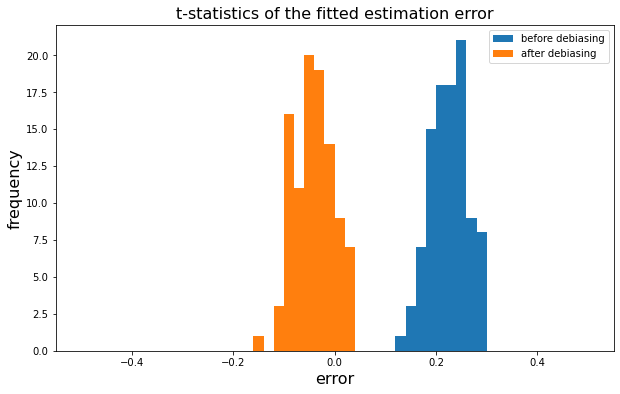

In [64]:
import matplotlib.pyplot as plt
plt.figure(figsize = (10, 6))
plt.hist(error_avg[0], bins = 50, range = (-0.5, 0.5), label = 'before debiasing')
plt.hist(error_avg[1], bins = 50, range = (-0.5, 0.5), label = 'after debiasing')
plt.legend()
plt.title('t-statistics of the fitted estimation error', fontsize = 16)
plt.xlabel('error', fontsize = 16)
plt.ylabel('frequency', fontsize = 16)
plt.show()

In [25]:
import numpy as np
import pandas as pd

sample_size = 200
df = pd.read_csv(f'nv_{sample_size}.csv')
df_array = np.array(df)

df_avg = np.mean(df_array, axis = 0)
print('SAA', df_avg[1:10])
print('normal', df_avg[10:19])
print('exp', df_avg[19:28])
print('exp_OS', df_avg[28:37])

SAA [ 0.45370899 -0.20563984  0.         -0.45615882 -0.30439798 -0.26174448
 -0.21814711 -0.17623383 -0.16334219]
normal [ 0.25593949 -0.14339199  0.05661825 -0.34527033 -0.2403804  -0.22260568
 -0.20920337 -0.1560828  -0.14494499]
exp [ 0.03272688 -0.06393215 -0.06728155 -0.07464424 -0.06728136 -0.06173775
 -0.06104836 -0.0619887  -0.05021198]
exp_OS [ 0.03593056 -0.05980881 -0.06370687 -0.34524896 -0.19847468 -0.15008259
 -0.13286734 -0.08866377 -0.0608064 ]


[94.28165655  3.39462296 95.77297076  1.70119394]


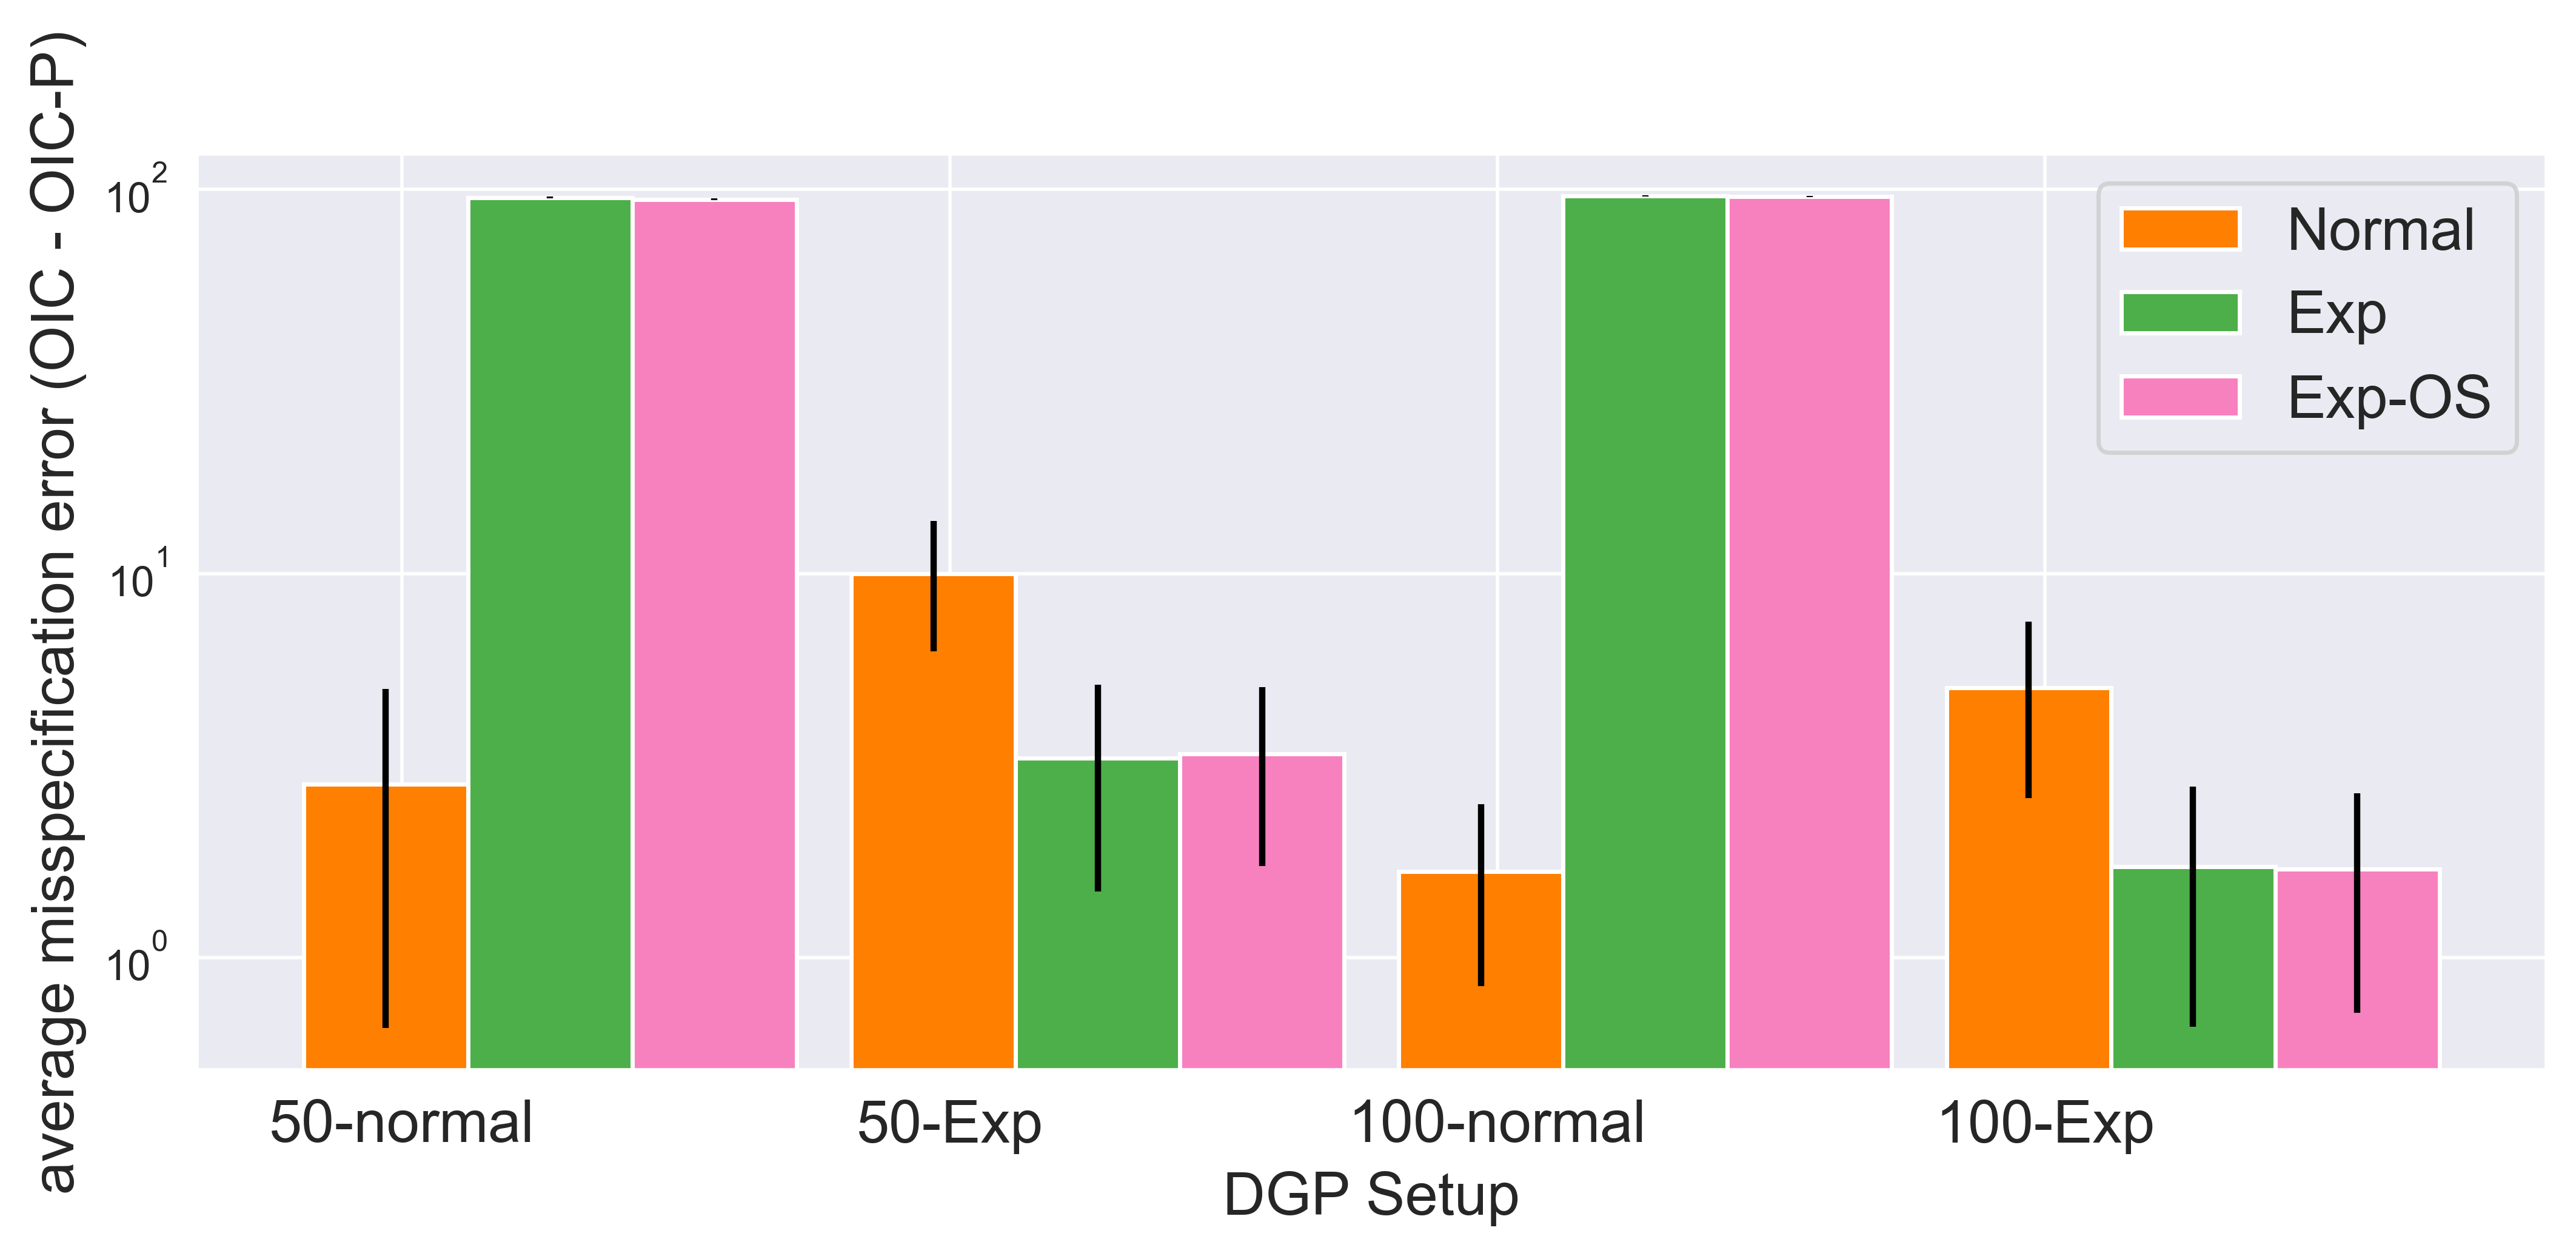

In [34]:
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt

sample_num = 100
mode = 'normal'
file_path = 'output/nv'
#fold_nums = [2, 3, 4, 5, 10, sample_num]
fold_nums = [5, 10, sample_num]

import seaborn as sns


sns.set_style('darkgrid')

btsp = [10, 50]

method_list = ['SAA', 'Normal', 'Exp', 'Exp-OS']
eval_list = ['EM', 'OIC', 'OIC-P'] + ["CV" + str(fold_num) for fold_num in fold_nums] + \
                ['B' + str(btsp_val) for btsp_val in btsp] + ['jck']


eval_list2 = [''] + eval_list

    #method_id = np.arange(1, len(eval_list) + 1)

i = 3
width = 0.3
x = np.arange(4)

fig, ax = plt.subplots(figsize = (10, 4), dpi = 500)

colors = ['#377eb8', '#ff7f00', '#4daf4a',
          '#f781bf', '#a65628', '#984ea3',
          '#999999', '#e41a1c', '#dede00']


for j in range(1, len(method_list)):
    method_perform = np.zeros(4)
    method_perform_std = np.zeros(4)

    sample_num = 50
    for i, mode in enumerate(['normal', 'exponential']):
        df_eval = pd.read_csv(f"{file_path}/nv_evaluate2_{sample_num}_{mode}.csv")
        method = method_list[j]


        series_id2 = (len(eval_list)  + 1) * j + 3 + 1

        mis_error = np.array(df_eval[f'{series_id2}']) - np.array(df_eval[f'{series_id2 - 1}'])
        method_perform[i] = np.mean(np.abs(mis_error))
        method_perform_std[i] = np.std(np.abs(mis_error)) 

    sample_num = 100
    for i, mode in enumerate(['normal', 'exponential']):
        df_eval = pd.read_csv(f"{file_path}/nv_evaluate2_{sample_num}_{mode}.csv")
        method = method_list[j]


        series_id2 = (len(eval_list)  + 1) * j + 3 + 1

        mis_error = np.array(df_eval[f'{series_id2}']) - np.array(df_eval[f'{series_id2 - 1}'])
        method_perform[i + 2] = np.mean(np.abs(mis_error))
        method_perform_std[i + 2] = np.std(np.abs(mis_error)) 
        #/ math.sqrt(len(df_eval[f'{series_id2}']))


    ax.bar(x + (-1.1 + j) * width, method_perform, width = 0.3, label = method,
            color = colors[j])

    ax.errorbar(x + (-1.1 + j) * width, method_perform, yerr = method_perform_std, fmt = 'none', color = 'black')
 
print(method_perform)


ax.set_ylabel('average misspecification error (OIC - OIC-P)', fontsize = 14)
ax.set_xlabel(f'DGP Setup', fontsize = 14)
ax.set_yscale('log')
ax.set_xticks(x)
ax.set_xticklabels(['50-normal', '50-Exp', '100-normal', '100-Exp'], fontsize = 14)
ax.legend(loc = 'upper right', fontsize = 14)
#plt.show()
plt.savefig(f'figures/nv/mainmis_{mode}.pdf')


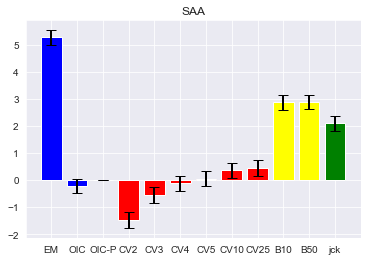

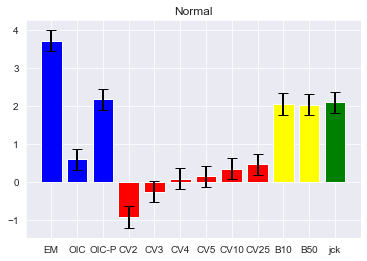

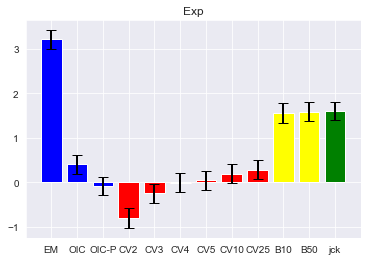

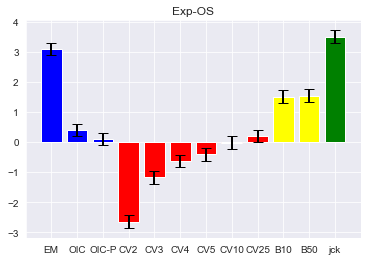

In [54]:
# newsvendor order
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt

sample_num = 25
mode = 'normal'
file_path = 'output/nv'
fold_nums = [2, 3, 4, 5, 10, sample_num]

btsp = [10, 50]


method_list = ['SAA', 'Normal', 'Exp', 'Exp-OS']
eval_list = ['EM', 'OIC', 'OIC-P'] + ["CV" + str(fold_num) for fold_num in fold_nums] + \
                ['B' + str(btsp_val) for btsp_val in btsp] + ['jck']

fig, ax = plt.subplots(figsize = (10, 6), dpi = 500)
color_map = 3 * ['blue'] + len(fold_nums) * ['red'] + 2 * ['yellow'] + 1 * ['green']
df = pd.read_csv(f"{file_path}/nv2_{sample_num}_{mode}.csv")
df2 = pd.read_csv(f"{file_path}/nv3_{sample_num}_{mode}.csv") 
#print(df['0'])
error_params = dict(elinewidth = 2, capsize = 5)
for i, method in enumerate(method_list):
    method_id = np.arange(1, len(eval_list) + 1)
    method_perform = np.zeros(len(eval_list))
    method_perform_std = np.zeros(len(eval_list))
    for j, eval_model in enumerate(eval_list):
        series_id = len(eval_list) * i + j
        if method != 'Exp' or eval_model != 'OIC-P':
            method_perform[j] = np.mean(np.array(df[f'{series_id}']))
            method_perform_std[j] = np.std(np.array(df[f'{series_id}'])) / math.sqrt(len(np.array(df[f'{series_id}'])))
        else:
            method_perform[j] = np.mean(np.array(df2[f'{series_id}']))
            method_perform_std[j] = np.std(np.array(df2[f'{series_id}'])) / math.sqrt(len(np.array(df2[f'{series_id}'])))
    fig = plt.figure()
    plt.bar(method_id, method_perform, yerr = method_perform_std, color = color_map, error_kw = error_params, tick_label = eval_list)
    plt.title(method)

    plt.savefig(f'figures/nv/nv2_{method}_{sample_num}_{mode}.pdf', dpi = 1000)






    



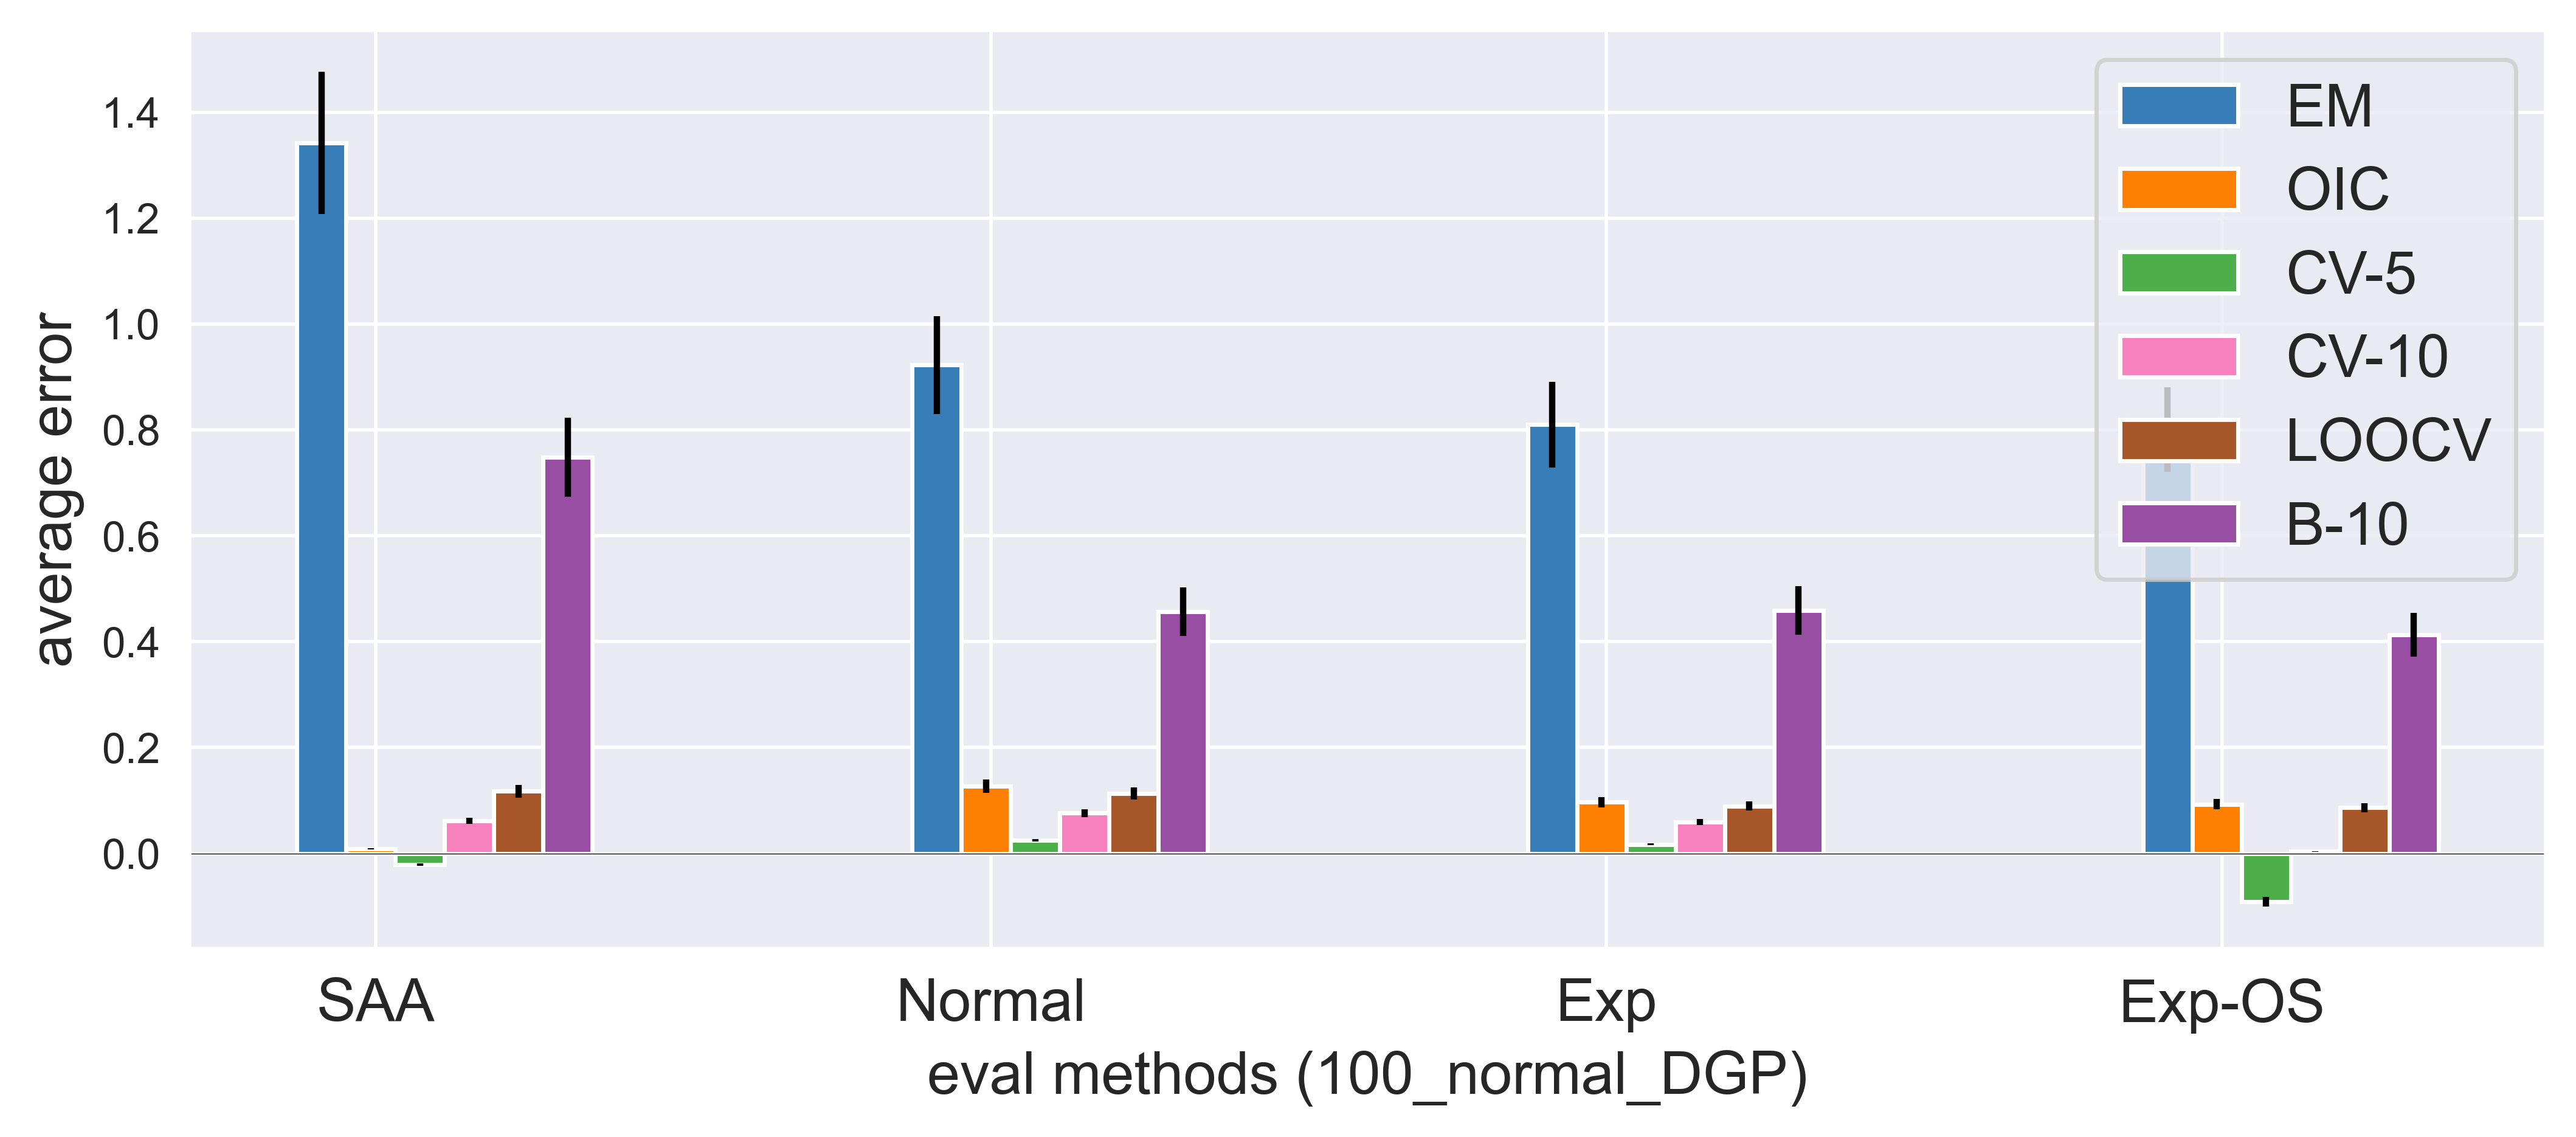

In [33]:
# newsvendor figure main text
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_style('darkgrid')


mode = 'normal'
sample_num = 100
file_path = 'output/nv'

method_list = ['SAA', 'Normal', 'Exp', 'Exp-OS']
eval_list = ['EM', 'OIC', 'CV-5', 'CV-10', 'LOOCV','B-10']
eval_map_key = [0, 1, 6, 7, 8, 9]
fig, ax = plt.subplots(figsize = (10, 4), dpi = 500)
width2 = 0.08
x = np.arange(len(method_list))

colors = ['#377eb8', '#ff7f00', '#4daf4a',
          '#f781bf', '#a65628', '#984ea3',
          '#999999', '#e41a1c', '#dede00']


df = pd.read_csv(f"{file_path}/nv2_{sample_num}_{mode}.csv")
df2 = pd.read_csv(f"{file_path}/nv3_{sample_num}_{mode}.csv")

#output_res_array = np.zeros((len(eval_list), len(method_list)))

mis_eval = np.zeros((3, 2))
for i, model in enumerate(eval_list):
    output_res_array = np.zeros(len(method_list))
    method_perform_std = np.zeros(len(method_list))
    for j, alpha in enumerate(method_list):
        if model == 'OIC-P' and alpha == 'Exp':
            output_res_array[j] = np.mean(np.array(df2[f'{j * 12 + eval_map_key[i]}']))

            method_perform_std[j] = np.mean(np.array(df2[f'{j * 12 + eval_map_key[i]}'])) / math.sqrt(sample_num)
        else:
            output_res_array[j] = np.mean(np.array(df[f'{j * 12 + eval_map_key[i]}']))

            method_perform_std[j] = np.mean(np.array(df[f'{j * 12 + eval_map_key[i]}'])) / math.sqrt(sample_num)
    ax.bar(x + (-1.1 + i) * width2, output_res_array, width = width2, label = model,
            color = colors[i])

    ax.errorbar(x + (-1.1 + i) * width2, output_res_array, yerr = method_perform_std, fmt = 'none', color = 'black')
    
ax.set_ylabel('average error', fontsize = 14)
ax.set_xlabel(f'eval methods ({sample_num}_{mode}_DGP)', fontsize = 14)
ax.set_xticks(x)
ax.set_xticklabels(method_list, fontsize = 14)
plt.axhline(0, linewidth = 0.2, color = 'black')
ax.legend(loc = 'upper right', fontsize = 14)

plt.savefig(f'figures/nv/main_{sample_num}_{mode}.pdf')
#ax.set_ylim([0.6, 1.0])
#plt.savefig('figures/' + dataset + '_' + method + '_' + perform_metric + '.pdf')



In [ ]:
# newsvendor figure main text
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_style('darkgrid')


mode = 'normal'
sample_num = 50
file_path = 'output/nv'

method_list = ['Normal', 'Exp', 'Exp-OS']
eval_list = ['EM', 'OIC', 'OIC-P', 'CV-5', 'CV-10', 'LOOCV','B-10']
eval_map_key = [1, 2]
fig, ax = plt.subplots(figsize = (10, 6), dpi = 500)
width = 0.075
x = np.arange(len(method_list))

colors = ['#377eb8', '#ff7f00', '#4daf4a',
          '#f781bf', '#a65628', '#984ea3',
          '#999999', '#e41a1c', '#dede00']


df = pd.read_csv(f"{file_path}/nv2_{sample_num}_{mode}.csv")
df2 = pd.read_csv(f"{file_path}/nv3_{sample_num}_{mode}.csv")

#output_res_array = np.zeros((len(eval_list), len(method_list)))

mis_eval = np.zeros((3, 2))

for j, alpha in enumerate(method_list):
    for i, model in enumerate(['OIC', 'OIC-P']):
        if model == 'OIC-P' and alpha == 'Exp':
            np.array(df2[f'{j * 12 + eval_map_key[i]}'])

        else:
            np.array(df[f'{j * 12 + eval_map_key[i]}'])


    

In [5]:
# portfolio
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt

sample_num = 50
port_num = 10
file_path = 'output/portfolio'
fold_nums = [2, 3, 4, 5, 10, sample_num]

btsp = [10, 50]


# method_list = ['SAA', 'Normal', 'Exp', 'Exp-OS']
# eval_list = ['EM', 'OIC', 'OIC-P'] + ["CV" + str(fold_num) for fold_num in fold_nums] + \
#                 ['B' + str(btsp_val) for btsp_val in btsp] + ['jck']

# color_map = 3 * ['blue'] + len(fold_nums) * ['red'] + 2 * ['yellow'] + 1 * ['green']
# df = pd.read_csv(f"{file_path}/portfolio_{sample_num}.csv")
# #print(df['0'])
# error_params = dict(elinewidth = 2, capsize = 5)
# for i, method in enumerate(method_list):
#     method_id = np.arange(1, len(eval_list) + 1)
#     method_perform = np.zeros(len(eval_list))
#     method_perform_std = np.zeros(len(eval_list))
#     for j, eval_model in enumerate(eval_list):
#         series_id = len(eval_list) * i + j
#         method_perform[j] = np.mean(np.array(df[f'{series_id}']))
#         method_perform_std[j] = np.std(np.array(df[f'{series_id}'])) / math.sqrt(len(np.array(df[f'{series_id}'])))
#     fig = plt.figure()
#     plt.bar(method_id, method_perform, yerr = method_perform_std, color = color_map, error_kw = error_params, tick_label = eval_list)
#     plt.title(method)

df = pd.read_csv(f"{file_path}/portfolio_{port_num}_{sample_num}_test.csv")
method_list = ['SAA', 'uniform', 'block', 'param', 'DRO5']

eval_list = ['EM', 'Oracle', 'OIC', '5-CV']
origin_index = [0, 2, 4]
origin_col = [0, 1, 2, 3, 4, 7]
for i, method in enumerate(method_list):
    for j, eval_model in enumerate(eval_list[1:]):
        series_id = 7 * origin_col[i] + origin_index[j]
        base_id = 7 * origin_col[i] + 1
        print('result ', method, eval_model, np.mean(np.array(df[f'{series_id}']) - np.array(df[f'{base_id}'])), np.std(np.array(df[f'{series_id}']) - np.array(df[f'{base_id}'])))





    #plt.savefig(f'figures/nv/nv2_{method}_{sample_num}_{mode}.pdf', dpi = 1000)

result  SAA Oracle 0.09058644879369684 0.08625536697593882
result  SAA OIC 0.09601177554875977 0.025640441058169722
result  SAA 5-CV 0.11554113735551222 0.03150591677149107
result  uniform Oracle 0.03583273286884245 0.09323545897732789
result  uniform OIC 0.049833342290561834 0.014648041802045396
result  uniform 5-CV 0.05986882263582784 0.020940558530626627
result  block Oracle 0.06976188746511329 0.09315734177837927
result  block OIC 0.07785969781478043 0.02242806312187105
result  block 5-CV 0.0919344016419581 0.02755064134885149
result  param Oracle 0.029568231547253743 0.19093090748836622
result  param OIC 0.0654490881237987 0.021649594520284168
result  param 5-CV 0.057690293203764884 0.02450682079010152
result  DRO5 Oracle 0.0884936514565065 0.07544443841004148
result  DRO5 OIC 0.08330073192903434 0.021679828224869434
result  DRO5 5-CV 0.1144261115781495 0.03013650337056005


50 2 0
50 2 1
50 2 2
50 2 3
50 2 4
50 2 5
50 2 6
50 2 7
50 2 8
50 2 9
50 2 10
50 2 11
50 2 12
50 2 13
50 2 14
50 2 15
50 2 16
50 2 17
50 2 18
50 2 19
50 2 20
50 2 21
50 2 22
50 2 23
50 2 24
50 2 25
50 2 26
50 2 27
50 2 28
50 2 29
50 2 30
50 2 31
50 2 32
50 2 33
50 2 34
50 2 35
50 2 36
50 2 37
50 2 38
50 2 39
50 2 40
50 2 41
50 2 42
50 2 43
50 2 44
50 2 45
50 2 46
50 2 47
50 2 48
50 2 49
50 4 0
50 4 1
50 4 2
50 4 3
50 4 4
50 4 5
50 4 6
50 4 7
50 4 8
50 4 9
50 4 10
50 4 11
50 4 12
50 4 13
50 4 14
50 4 15
50 4 16
50 4 17
50 4 18
50 4 19
50 4 20
50 4 21
50 4 22
50 4 23
50 4 24
50 4 25
50 4 26
50 4 27
50 4 28
50 4 29
50 4 30
50 4 31
50 4 32
50 4 33
50 4 34
50 4 35
50 4 36
50 4 37
50 4 38
50 4 39
50 4 40
50 4 41
50 4 42
50 4 43
50 4 44
50 4 45
50 4 46
50 4 47
50 4 48
50 4 49
50 6 0
50 6 1
50 6 2
50 6 3
50 6 4
50 6 5
50 6 6
50 6 7
50 6 8
50 6 9
50 6 10
50 6 11
50 6 12
50 6 13
50 6 14
50 6 15
50 6 16
50 6 17
50 6 18
50 6 19
50 6 20
50 6 21
50 6 22
50 6 23
50 6 24
50 6 25
50 6 26
50 6 27
50 6 2

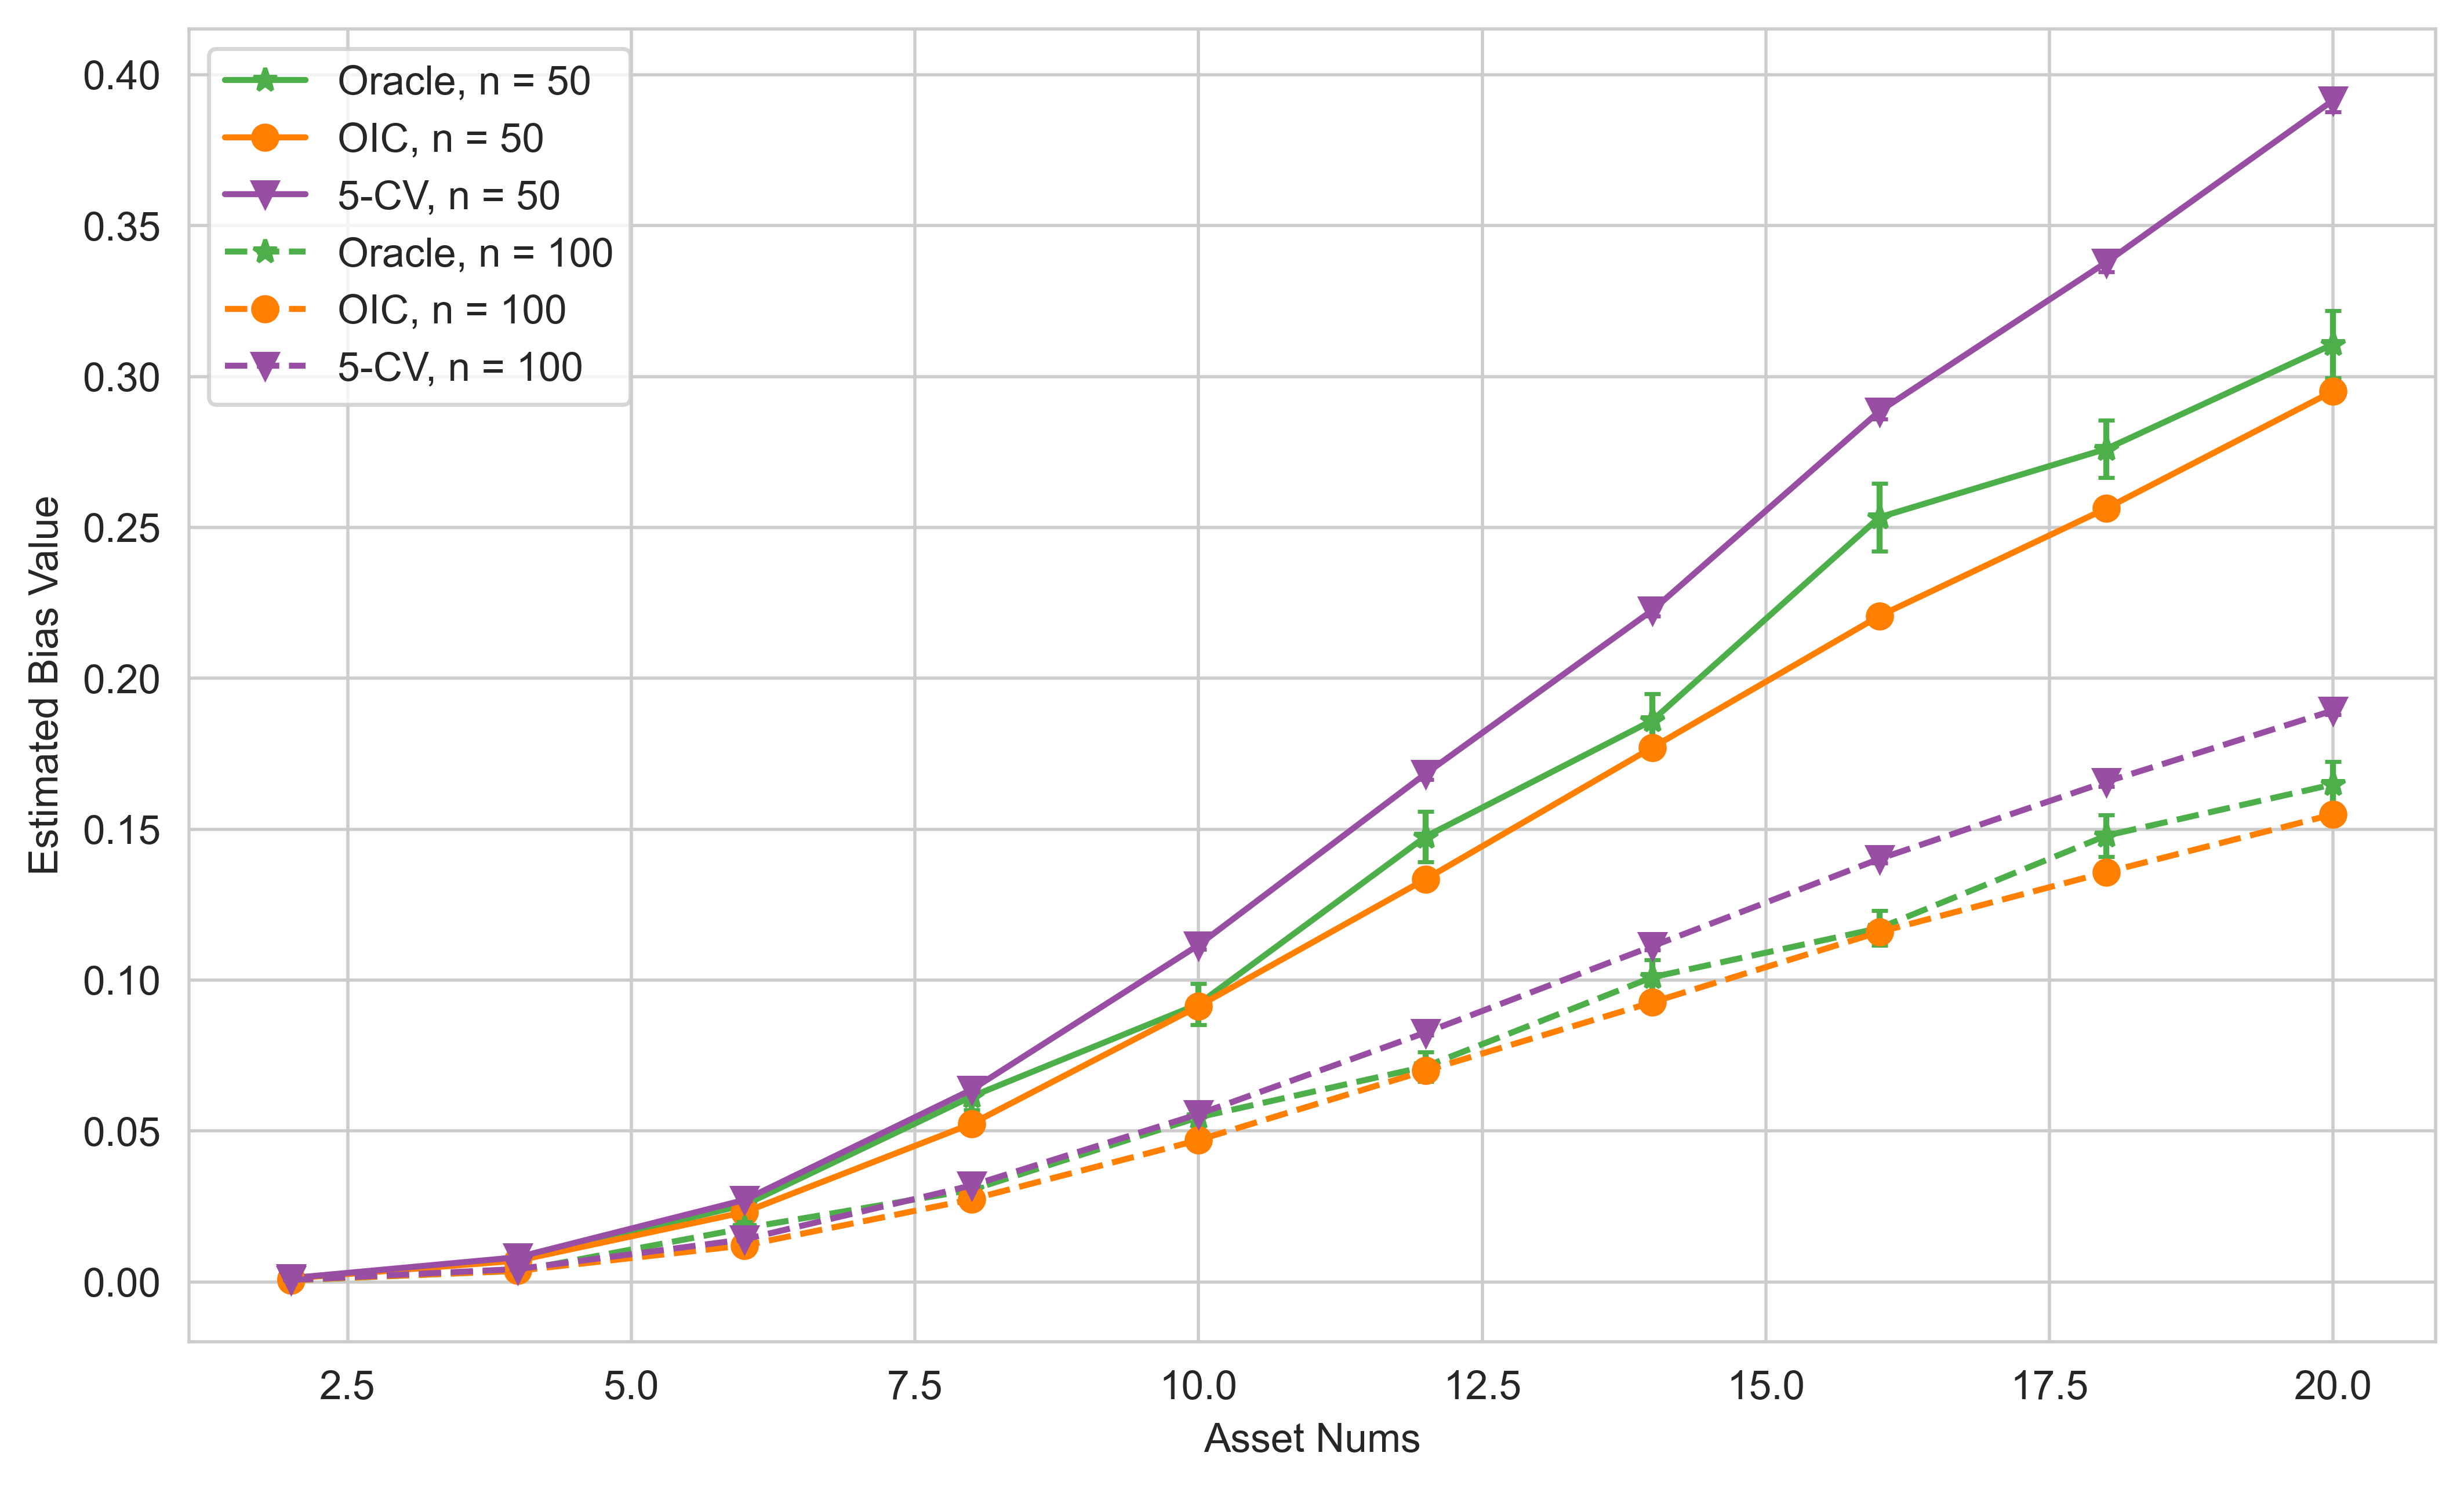

In [35]:
# mean-variance portfolio allocation
import pandas as pd
import numpy as np
import math
import cvxpy as cp

from torch.autograd.functional import jacobian
from torch.autograd.functional import hessian
import torch
from scipy.stats import chi2, norm, multivariate_normal
from sklearn.neighbors import KernelDensity

from src.portfolio_model import mv_portfolio

import matplotlib.pyplot as plt
import seaborn as sns

#sample_num = 20
# base case: a

loop_num = 50
outer_num = 50



asset_nums = [2, 4, 6, 8, 10, 12, 14, 16, 18, 20]
#asset_nums = [6, 12]

sample_num = 50
eval_num = 1
choice_num = 3
lambda_1 = 1
lambda_2 = 2


# dro_coefs = [1, 3, 5]
# kfold_num = [2, 5, 10]

# TODO: vary sample size to be 
sample_num = 50

model_perform = np.zeros((outer_num, choice_num * eval_num))

final_perform_mean = np.zeros((2, len(asset_nums), eval_num * choice_num))
final_perform_std = np.zeros((2, len(asset_nums), eval_num * choice_num))

labels = ['Oracle', 'OIC', '5-CV']


def DGP(asset_num):
    asset_num0 = int(asset_num / 2)
    return_mean = np.random.uniform(0, 4, asset_num)
    cov_comp = np.random.rand(asset_num0, asset_num0) * 0.5
    return_cov = np.zeros((asset_num0, asset_num0))
    return_cov = np.dot(cov_comp, cov_comp.transpose())

    cov_comp = np.random.rand(asset_num0, asset_num0) * 0.5
    return_cov0 = np.zeros((asset_num0, asset_num0))    
    return_cov0 = np.dot(cov_comp, cov_comp.transpose())

    cov_all = np.zeros((asset_num, asset_num))
    cov_all[0:asset_num0, 0:asset_num0] = return_cov
    #= return_cov
    cov_all[asset_num0:, asset_num0:] = return_cov0

    return return_mean, cov_all


linestyle = ['-', '.']
for j, sample_num in enumerate([50, 100]):
    for i, asset_num in enumerate(asset_nums):
        for s in range(outer_num):
            print(sample_num, asset_num, s)
            model_inner = np.zeros((loop_num, choice_num * eval_num))
            for k in range(loop_num):
                return_mean, cov_all = DGP(asset_num)
                mv_model = mv_portfolio(return_mean, cov_all, lambda_1, lambda_2)
                data = mv_model.generate(sample_num)

                saa_sol = mv_model.saa_sol(data)
                model_inner[k][0] = mv_model.true_eval(saa_sol) - mv_model.sample_eval(saa_sol, data)
                model_inner[k][1] = mv_model.saa_correction(saa_sol, data)
                model_inner[k][2] = mv_model.CV_performance(data, 5, 'saa') - mv_model.sample_eval(saa_sol, data)
            
            model_perform[s] = np.mean(model_inner, axis = 0)


        final_perform_mean[j][i] = np.mean(model_perform, axis = 0)
        final_perform_std[j][i] = np.std(model_perform, axis = 0)

# fig = plt.figure(figsize = (10, 6), dpi = 500)
# sns.set_style('darkgrid')
# linestyles = ['-', '--']
# for j in range(2):


#     final_mean = final_perform_mean[j].T
#     final_std = final_perform_std[j].T

#     marker_choice = ['*', 'o', 'v', '1', '2', '3']
#     colors=['#4daf4a', '#ff7f00', '#984ea3', '#FFD43B', '#a65628', '#f781bf', '#e41a1c', '#377eb8']

#     for k in range(len(labels)):
#         plt.plot(asset_nums, final_mean[k], linestyles[j], label = labels[k] + f', n = {sample_num}', marker = marker_choice[k], color = colors[k])
#         #plt.errorbar(x = asset_nums, y = final_mean[k], yerr = final_std[k]/math.sqrt(outer_num), color = colors[k], capsize = 2)

fig = plt.figure(figsize = (10, 6), dpi = 500)
sns.set_style('whitegrid')
linestyles = ['-', '--']
sample_nums = [50, 100]
for j in range(2):


    final_mean = final_perform_mean[j].T
    final_std = final_perform_std[j].T

    marker_choice = ['*', 'o', 'v', '1', '2', '3']
    colors=['#4daf4a', '#ff7f00', '#984ea3', '#FFD43B', '#a65628', '#f781bf', '#e41a1c', '#377eb8']

    for k in range(len(labels)):
        plt.plot(asset_nums, final_mean[k], linestyles[j], label = labels[k] + f', n = {sample_nums[j]}', marker = marker_choice[k], color = colors[k])
        plt.errorbar(x = asset_nums, y = final_mean[k], fmt = 'None', yerr = final_std[k] / math.sqrt(outer_num), color = colors[k], capsize = 2)

plt.legend(loc = 'upper left')
plt.xlabel('Asset Nums')
plt.ylabel('Estimated Bias Value')

plt.savefig(f'figures/portfolio/test_saa2.pdf')

In [9]:
final_perform_mean


array([[[0.02711256, 0.02331086, 0.02789504],
        [0.15632001, 0.13446158, 0.16809359]],

       [[0.01018579, 0.01231653, 0.01427117],
        [0.07039996, 0.06933902, 0.08315329]]])

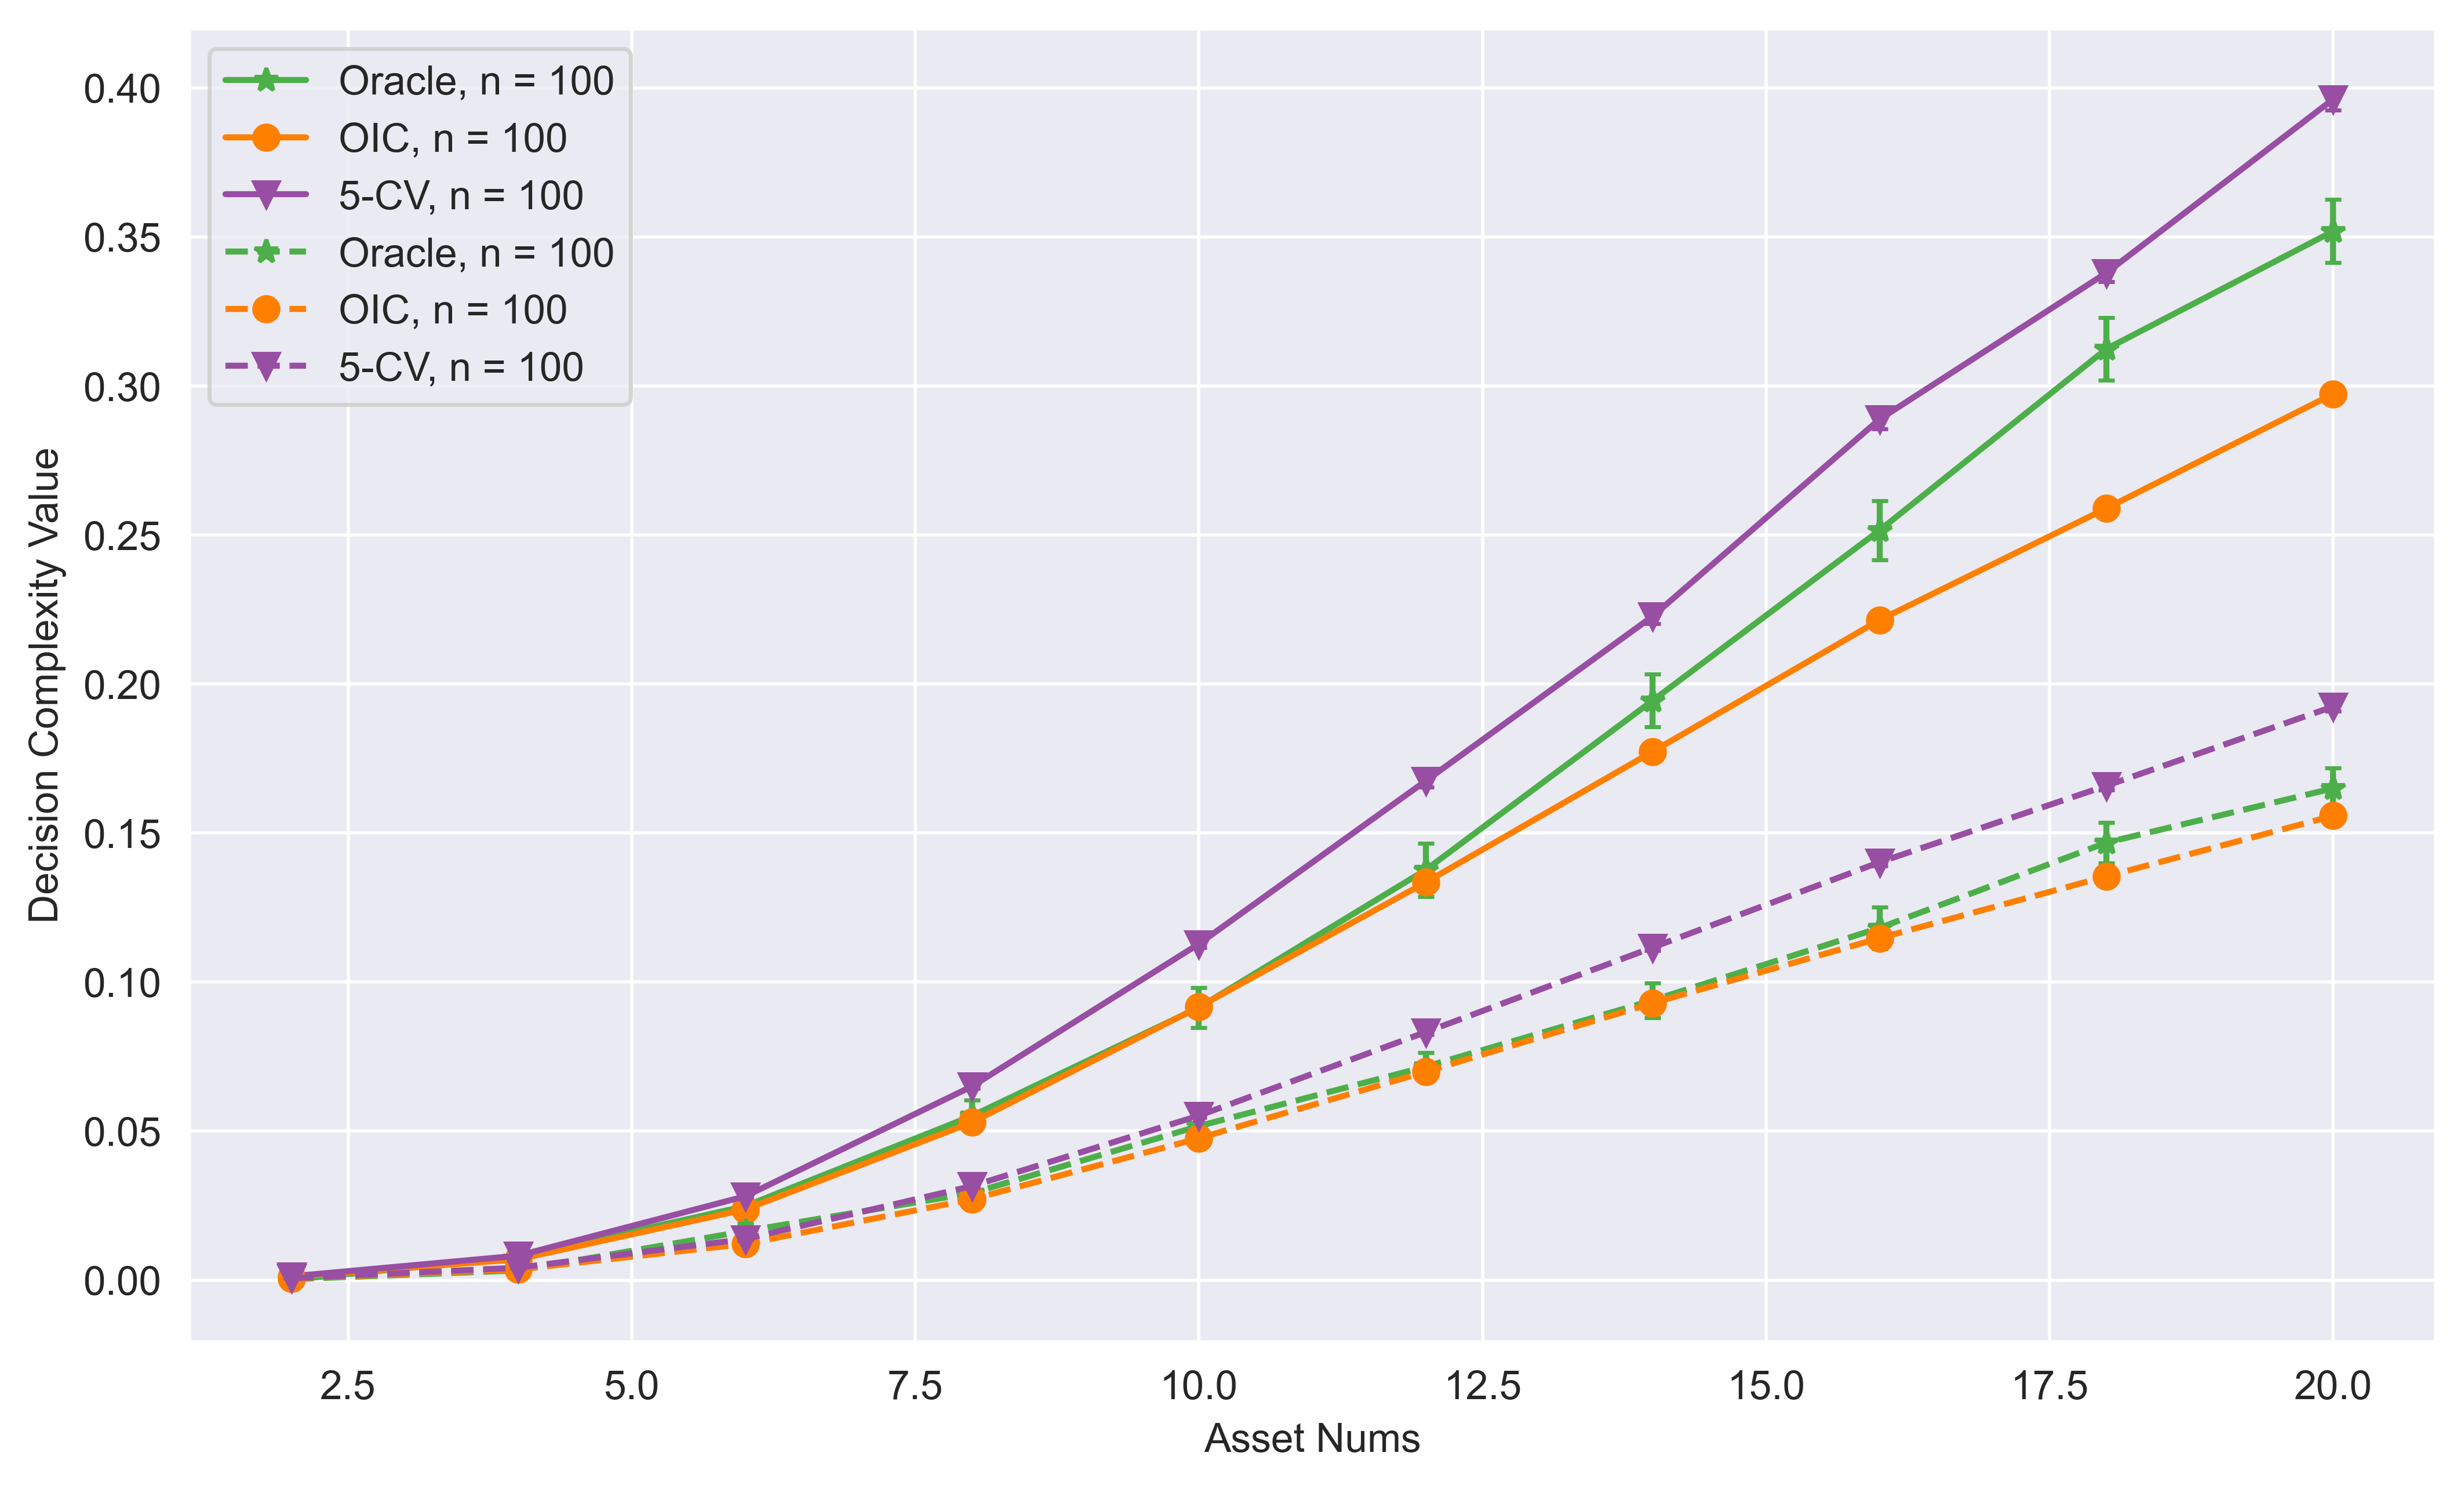

In [11]:
import pandas as pd
import numpy as np
import math

frac = [0.1, 0.3]

FILE_PATH = 'output/regression/regression'

model_classes = [['linear_1_1', 'ridge_1_1', 'linear_2_1', 'ridge_2_1'],\
                 ['linear_1_1', 'ridge_1_1', 'linear_2_5', 'ridge_2_1', 'ridge_2_5', 'nn_1_5']]

indexes = [0, 1, 2, 3]
index = 0
#eval_names = ['EM', 'OIC', '5-CV', 'Oracle', 'Oracle Comp.']
eval_names = ['EM', 'OIC', '5-CV', 'Oracle']
for index, eval_name in enumerate(eval_names):
    str_result = eval_name + '&'
    for i, frac_val in enumerate(frac):
        for model_name in model_classes[i]:
            if model_name != 'nn_1_5':
                df = pd.read_csv(f"{FILE_PATH}/result_{frac_val}_{model_name}.csv")
                if model_name in ['linear_2_1', 'ridge_2_1', 'linear_2_5', 'ridge_2_1', 'ridge_2_5'] and index == 1:
                    df['1'] = 2 * (df['1'] - df['0']) + df['0'] 

            else:
                df1 = pd.read_csv(f"{FILE_PATH}/result_{frac_val}_{model_name}.csv")
                df2 = pd.read_csv(f"{FILE_PATH}/result2_{frac_val}_{model_name}.csv")
                df = pd.concat([df1, df2])
                if index == 1:
                    df['1'] = 2 * (df['1'] - df['0']) + df['0'] 
            result_mean = np.mean(df[f'{index}']) * 100
            result_se = np.std(df[f'{index}']) / math.sqrt(len(df)) * 100
            str_result += "{:.1f}".format(result_mean) + '\scriptsize $\pm ' + "{:.1f}".format(result_se) + '$&'
    print(str_result[:-1] + '\\' + '\\')
                




EM&34.5\scriptsize $\pm 0.2$&34.2\scriptsize $\pm 0.2$&24.2\scriptsize $\pm 0.2$&24.4\scriptsize $\pm 0.2$&35.3\scriptsize $\pm 0.1$&35.1\scriptsize $\pm 0.1$&28.2\scriptsize $\pm 0.1$&28.2\scriptsize $\pm 0.1$&28.4\scriptsize $\pm 0.1$&27.2\scriptsize $\pm 0.4$\\
OIC&36.6\scriptsize $\pm 0.2$&36.2\scriptsize $\pm 0.2$&41.0\scriptsize $\pm 0.3$&40.4\scriptsize $\pm 0.3$&36.1\scriptsize $\pm 0.1$&35.9\scriptsize $\pm 0.1$&35.5\scriptsize $\pm 0.1$&35.4\scriptsize $\pm 0.1$&35.4\scriptsize $\pm 0.1$&35.3\scriptsize $\pm 1.5$\\
5-CV&37.3\scriptsize $\pm 0.3$&36.8\scriptsize $\pm 0.2$&83.8\scriptsize $\pm 13.7$&59.9\scriptsize $\pm 3.5$&36.2\scriptsize $\pm 0.1$&36.0\scriptsize $\pm 0.1$&40.7\scriptsize $\pm 0.9$&41.2\scriptsize $\pm 1.4$&41.6\scriptsize $\pm 1.2$&39.7\scriptsize $\pm 2.1$\\
Oracle&36.8\scriptsize $\pm 0.0$&36.7\scriptsize $\pm 0.0$&62.0\scriptsize $\pm 1.8$&58.8\scriptsize $\pm 1.5$&35.9\scriptsize $\pm 0.1$&36.0\scriptsize $\pm 0.1$&38.1\scriptsize $\pm 0.6$&39.2\scripts